# Neural aids for MCMC: NeuTra and neural IMH

Gradient-based samplers such as NUTS are local: they follow the geometry of the
target one leapfrog step at a time. Two kinds of target break them:

- **Bad geometry.** When the curvature changes by orders of magnitude across the
  support (Neal's funnel), no single step size and mass matrix suits every
  region. NUTS either takes tiny steps everywhere or misses the narrow parts.
- **Separated modes.** A local kernel started in one mode of a mixture almost
  never crosses the low-density gap to another one.

A normalizing flow can help with both, and in both cases MCMC stays exact:

1. **NeuTra** fits a flow $T$ to the target with variational inference and
   runs NUTS on the pulled-back density $\tilde p(z) = p(T(z))\,|\det J_T(z)|$,
   which is close to a standard normal when the flow is good.
2. **Neural independent Metropolis-Hastings** uses a flow as a global proposal
   and trains it on the chain's own output while the chain runs.

Both are built from the same three pieces, so everything below is one compiled
program with no Python training loop:

- `probjax.inference.neural.density(flow)` splits a flow into a pure
  `Density(sample, logpdf)` and its parameter pytree. The weights are just
  kernel `params`, so they can live in a `jax.lax.scan` and be `vmap`-ed over
  chains.
- `flow_vi` is an ordinary kernel whose step is one optimizer step, so the
  variational fit runs through the same `run` as every sampler.
- `fit_adaptor` is an ordinary adaptor that trains those params on the chain's
  output, during warmup or while sampling.

This notebook runs on CPU in about a minute, with the same warmup and draw
budgets for each comparison.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax
from flax import nnx

jax.config.update("jax_platform_name", "cpu")

from probjax.inference import fit_adaptor, flow_vi, imh, maximum_likelihood, neutra, nuts, run, warmup
from probjax.inference.diagnostics import effective_sample_size, rhat
from probjax.inference.mcmc.imh import imh_data
from probjax.inference.neural import bijection, density
from probjax.nn import nsf, realnvp

COLORS = {"reference": "0.75", "nuts": "tab:orange", "neutra": "tab:blue", "flow": "tab:green"}

## 1. Neal's funnel defeats plain NUTS

Neal's funnel in $D = 10$ dimensions: $v \sim \mathcal N(0, 3^2)$ and
$x_i \mid v \sim \mathcal N(0, e^{v})$ for $i = 1, \dots, 9$. At $v = -6$ the
$x_i$ have standard deviation $0.05$; at $v = 6$, $20$. The region that matters
for the hard direction is the narrow neck at negative $v$.

We run four chains of NUTS with the default Stan-style window warmup
(1000 steps), then draw 2000 samples per chain. Besides positions we collect
the per-step divergence flag and the number of leapfrog steps, i.e. gradient
evaluations.

In [2]:
DIM = 10
NUM_CHAINS, NUM_WARMUP, NUM_DRAWS = 4, 1000, 2000


def funnel_logdensity(z):
    v, x = z[0], z[1:]
    return jax.scipy.stats.norm.logpdf(v, 0.0, 3.0) + jax.scipy.stats.norm.logpdf(x, 0.0, jnp.exp(v / 2)).sum()


# Exact draws for reference.
key_v, key_x = jax.random.split(jax.random.key(0))
v_ref = 3.0 * jax.random.normal(key_v, (20_000,))
x_ref = jax.random.normal(key_x, (20_000,)) * jnp.exp(v_ref / 2)

Every chain is warmed up and run independently; `jax.vmap` over the key runs
the four of them in one compiled program.

In [3]:
def sample_nuts(logdensity, key):
    kernel = nuts(logdensity)

    def one_chain(key):
        key_init, key_warmup, key_run = jax.random.split(key, 3)
        state = kernel.init(key_init, jax.random.normal(key_init, (DIM,)))
        warm = warmup(key_warmup, kernel, state, kernel.init_params(state), NUM_WARMUP)
        collect = ("position", "is_divergent", "num_integration_steps")
        return run(key_run, kernel, warm.state, warm.params, NUM_DRAWS, collect=collect).trace

    return jax.vmap(one_chain)(jax.random.split(key, NUM_CHAINS))


def summarize(name, positions, trace):
    v = positions[..., 0]
    stats = dict(
        ess_v=float(effective_sample_size(v)),
        rhat_v=float(rhat(v)),
        var_v=float(v.var()),
        min_v=float(v.min()),
        divergences=int(trace["is_divergent"].sum()),
        grad_evals=int(trace["num_integration_steps"].sum()),
    )
    print(f"{name:>12}: " + ", ".join(f"{k}={v:.3g}" for k, v in stats.items()))
    return stats


start = time.perf_counter()
nuts_trace = jax.block_until_ready(sample_nuts(funnel_logdensity, jax.random.key(1)))
nuts_seconds = time.perf_counter() - start
nuts_positions = nuts_trace["position"]
results = {"NUTS": summarize("NUTS", nuts_positions, nuts_trace)}
results["NUTS"]["seconds"] = nuts_seconds
print(f"wall time incl. compilation: {nuts_seconds:.1f}s  (truth: var_v = 9)")

        NUTS: ess_v=75, rhat_v=1.07, var_v=6.88, min_v=-4.49, divergences=15, grad_evals=3.34e+05
wall time incl. compilation: 2.1s  (truth: var_v = 9)


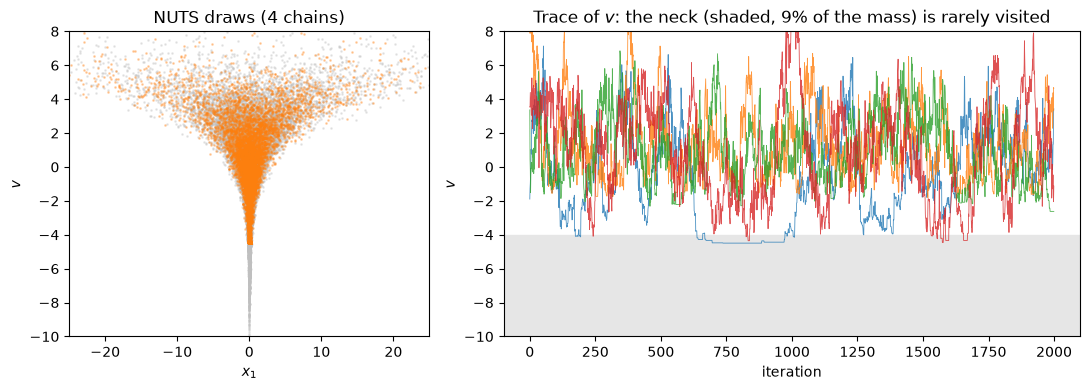

In [4]:
def funnel_scatter(ax, positions, color, title):
    ax.scatter(x_ref, v_ref, s=1, color=COLORS["reference"], alpha=0.3, rasterized=True, label="exact")
    ax.scatter(positions[..., 1].ravel(), positions[..., 0].ravel(), s=1, color=color, alpha=0.3, rasterized=True)
    ax.set(xlim=(-25, 25), ylim=(-10, 8), xlabel="$x_1$", ylabel="$v$", title=title)


fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.6]})
funnel_scatter(axes[0], nuts_positions, COLORS["nuts"], "NUTS draws (4 chains)")
for chain in range(NUM_CHAINS):
    axes[1].plot(nuts_positions[chain, :, 0], lw=0.6, alpha=0.8)
axes[1].axhspan(-10, -4, color="0.9", zorder=0)
axes[1].set(xlabel="iteration", ylabel="$v$", ylim=(-10, 8), title="Trace of $v$: the neck (shaded, 9% of the mass) is rarely visited")
plt.tight_layout()
plt.show()

The chains never reach deep into the neck, so the variance of $v$ is badly
underestimated, the effective sample size of $v$ is below a hundred out of
8000 draws, $\hat R$ flags the disagreement between chains, and NUTS reports
divergent transitions: the classic symptoms.

## 2. NeuTra: fix the geometry, not the sampler

### Fit a flow by variational inference

`flow_vi` minimises the reparameterised reverse KL,
$\mathbb E_{q}[\log q(x) - \log p(x)]$, over the parameters of a normalizing
flow. It is a kernel like any other: its state holds the flow's parameters and
the optimizer state, each step is one Adam step, and `run` drives it and
collects the `loss` it reports. We use a RealNVP-style affine coupling flow (`realnvp`): both of its
directions cost one network pass, which matters because NeuTra evaluates the
flow at every leapfrog step. (Autoregressive flows such as `maf`/`nsf` invert
sequentially, one pass per dimension.)

The objective is $\mathrm{KL}(q\,\|\,p) - \log Z$, so only its trend is
meaningful: it should go down and flatten. Do not stop it early: with 1000
steps instead of 3000 the downstream NeuTra ESS of $v$ varied from about 200 to
3200 across VI seeds, while 3000 steps gave 1600 to 7200.

VI: 2.2s, 192000 target-gradient evaluations
flow alone: var_v = 7.80, min_v = -7.93  (truth: 9)


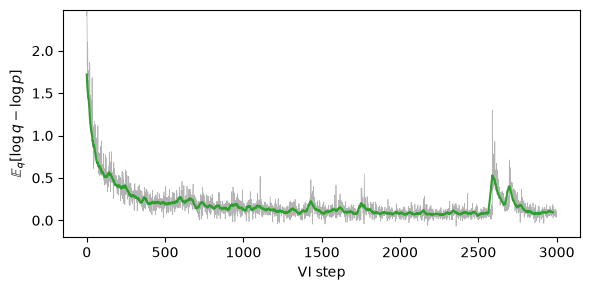

In [5]:
NUM_VI_STEPS, VI_SAMPLES = 3000, 64

flow = realnvp(DIM, 4, rngs=nnx.Rngs(0))
family, initial_params = density(flow)
vi_kernel = flow_vi(funnel_logdensity, family, optax.adam(1e-3), num_samples=VI_SAMPLES)

start = time.perf_counter()
vi_result = jax.block_until_ready(
    run(jax.random.key(2), vi_kernel, vi_kernel.init(initial_params), None, NUM_VI_STEPS, collect=("loss",))
)
vi_seconds = time.perf_counter() - start
fitted_params, objective = vi_result.state.params, vi_result.trace["loss"]
flow_draws = jax.vmap(family.sample, (0, None))(jax.random.split(jax.random.key(3), 8000), fitted_params)
print(f"VI: {vi_seconds:.1f}s, {NUM_VI_STEPS * VI_SAMPLES} target-gradient evaluations")
print(f"flow alone: var_v = {flow_draws[:, 0].var():.2f}, min_v = {flow_draws[:, 0].min():.2f}  (truth: 9)")

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(objective, color="0.7", lw=0.5)
ax.plot(jnp.convolve(objective, jnp.ones(25) / 25, mode="valid"), color=COLORS["flow"])
ax.set(xlabel="VI step", ylabel=r"$\mathbb{E}_q[\log q - \log p]$", ylim=(None, float(objective[:20].max())))
plt.tight_layout()
plt.show()

Reverse KL is mode-seeking, so the flow under-covers: its variance of $v$ is
too small. Used as an answer on its own it would be biased. NeuTra uses it only
as a change of variables.

### Run NUTS in the flow's latent space

`bijection(flow)` gives the flow's map $z \mapsto (T(z), \log|\det J_T(z)|)$
as a pure function of the parameters, and `neutra` uses it to return the
pulled-back log-density and the map back to the target. Because $z \mapsto T(z)$ is a bijection and the Jacobian term is
included, NUTS on $\tilde p$ targets exactly $p$ after mapping draws through
$T$, however imperfect the flow is: a poor flow only costs efficiency. Same
chains, warmup and draw budget as before.

In [6]:
forward, _ = bijection(flow)
transform = neutra(funnel_logdensity, forward, fitted_params)

start = time.perf_counter()
neutra_trace = jax.block_until_ready(sample_nuts(transform.logdensity, jax.random.key(1)))
neutra_seconds = time.perf_counter() - start
neutra_positions = transform.forward(neutra_trace["position"])
results["NeuTra + NUTS"] = summarize("NeuTra+NUTS", neutra_positions, neutra_trace)
results["NeuTra + NUTS"]["seconds"] = neutra_seconds + vi_seconds
print(f"wall time incl. compilation: {neutra_seconds:.1f}s  (truth: var_v = 9)")

 NeuTra+NUTS: ess_v=5.57e+03, rhat_v=1, var_v=8.84, min_v=-8.49, divergences=7, grad_evals=5.72e+04
wall time incl. compilation: 5.7s  (truth: var_v = 9)


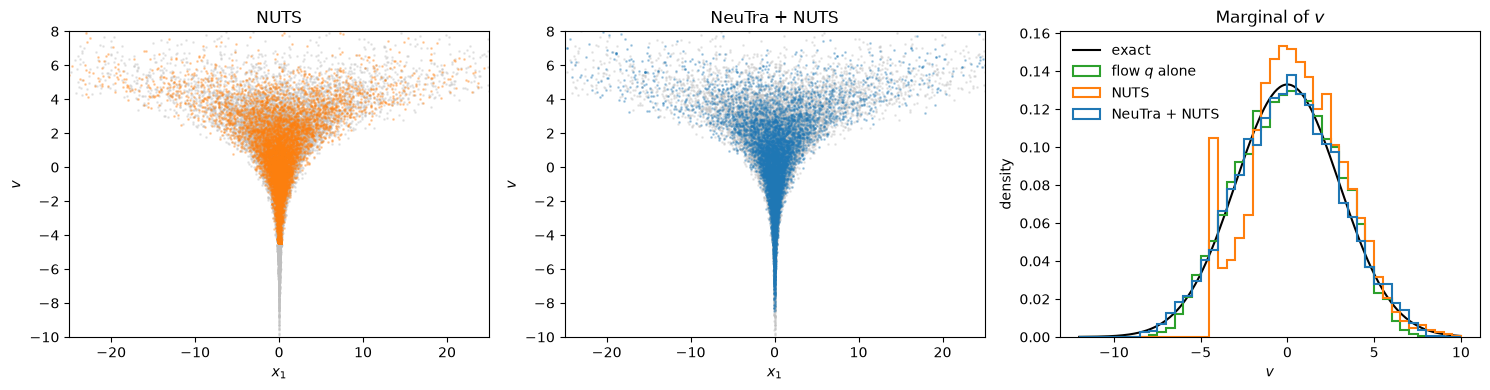

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
funnel_scatter(axes[0], nuts_positions, COLORS["nuts"], "NUTS")
funnel_scatter(axes[1], neutra_positions, COLORS["neutra"], "NeuTra + NUTS")

grid = jnp.linspace(-12, 10, 300)
axes[2].plot(grid, jax.scipy.stats.norm.pdf(grid, 0, 3), color="k", lw=1.5, label="exact")
bins = jnp.linspace(-12, 10, 45)
for draws, color, label in [
    (flow_draws[:, 0], COLORS["flow"], "flow $q$ alone"),
    (nuts_positions[..., 0].ravel(), COLORS["nuts"], "NUTS"),
    (neutra_positions[..., 0].ravel(), COLORS["neutra"], "NeuTra + NUTS"),
]:
    axes[2].hist(draws, bins=bins, density=True, histtype="step", lw=1.5, color=color, label=label)
axes[2].set(xlabel="$v$", ylabel="density", title="Marginal of $v$")
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

NeuTra recovers the neck that plain NUTS misses and the tail that the flow
alone under-covers. In latent coordinates the target is close to isotropic, so
the adapted step size suits the whole space and trajectories are several times
shorter. A few divergences remain: they mark the deep neck, where the flow is
least accurate, and are a useful hint that a better flow would help further.

The comparison below counts the cost honestly. The VI fit is not free: it used
more target gradients than the NeuTra sampling run itself. Wall times
include compilation, and NeuTra's includes the VI fit. On a funnel that is a
good trade; on an easy posterior it is not.

In [8]:
vi_grads = NUM_VI_STEPS * VI_SAMPLES
print(f"{'':>14} {'ESS(v)':>7} {'R-hat(v)':>9} {'var(v)':>7} {'diverg.':>8} {'sampling grads':>15} "
      f"{'ESS/1k grads':>13} {'ESS/s':>6}")
for name, s in results.items():
    print(f"{name:>14} {s['ess_v']:7.0f} {s['rhat_v']:9.3f} {s['var_v']:7.2f} {s['divergences']:8d} "
          f"{s['grad_evals']:15,d} {1000 * s['ess_v'] / s['grad_evals']:13.2f} {s['ess_v'] / s['seconds']:6.0f}")
total = results["NeuTra + NUTS"]["grad_evals"] + vi_grads
print(f"\nNeuTra incl. the VI fit: {total:,d} grads, "
      f"{1000 * results['NeuTra + NUTS']['ess_v'] / total:.2f} ESS / 1k grads")

                ESS(v)  R-hat(v)  var(v)  diverg.  sampling grads  ESS/1k grads  ESS/s
          NUTS      75     1.074    6.88       15         334,272          0.22     35
 NeuTra + NUTS    5570     1.001    8.84        7          57,152         97.46    710

NeuTra incl. the VI fit: 249,152 grads, 22.35 ESS / 1k grads


Each NeuTra gradient also passes through the flow, so per gradient it costs
more wall time than a plain one; per second it is still well ahead here.

## 3. Neural IMH: a global proposal for multimodal targets

NeuTra keeps the sampler local, so it inherits NUTS' difficulty with separated
modes. An *independent* Metropolis-Hastings kernel proposes from a fixed
distribution $q$ regardless of the current state and accepts with probability
$\min\{1, \frac{p(x')q(x)}{p(x)q(x')}\}$. If $q$ covers every mode, the chain
jumps between them freely; the closer $q$ is to $p$, the higher the acceptance
rate.

`imh(logdensity, proposal=q)` takes any `Density` as $q$, and its parameters
are the kernel's `params`. Its default adaptation is a `fit_adaptor` that
trains them by maximum likelihood on the chain's output, one Adam step per
transition. Each transition contributes its previous and proposed position,
weighted by the acceptance probability (`imh_data`), so rejected proposals
still teach $q$ where the target is. After adaptation the parameters are fixed,
and the chain is a valid MCMC kernel again.

The target is a ring of six Gaussians of standard deviation 0.5 at radius 6.

In [9]:
NUM_MODES = 6
angles = 2 * jnp.pi * jnp.arange(NUM_MODES) / NUM_MODES
mode_means = 6.0 * jnp.stack([jnp.cos(angles), jnp.sin(angles)], axis=-1)


def mixture_logdensity(z):
    component = jax.scipy.stats.norm.logpdf(z, mode_means, 0.5).sum(-1)
    return jax.scipy.special.logsumexp(component) - jnp.log(NUM_MODES)


def mode_occupancy(positions):
    nearest = jnp.argmin(((positions[:, None] - mode_means) ** 2).sum(-1), axis=1)
    return jnp.bincount(nearest, length=NUM_MODES) / len(positions)


MIX_WARMUP, MIX_DRAWS = 4000, 4000
start_position = mode_means[0]

First the local baseline: NUTS with its default warmup, started in one mode.

In [10]:
kernel = nuts(mixture_logdensity)
state = kernel.init(jax.random.key(0), start_position)
warm = warmup(jax.random.key(1), kernel, state, kernel.init_params(state), MIX_WARMUP)
mix_nuts = run(jax.random.key(2), kernel, warm.state, warm.params, MIX_DRAWS,
               collect=("position", "num_integration_steps")).trace
print("NUTS mode occupancy:", mode_occupancy(mix_nuts["position"]).round(3))

NUTS mode occupancy: [1. 0. 0. 0. 0. 0.]


### One chain, trained in the scan

The proposal is a small autoregressive spline flow. It starts as a standard
normal in standardized coordinates; setting the standardization scale to 6
makes the initial proposal a broad $\mathcal N(0, 6^2 I)$, so early proposals
land in every mode occasionally. Standardization statistics are buffers, not
`nnx.Param`s, so `density` keeps them fixed and training moves only the
network weights.

Passing the policy to `run` as `adaptor=` adapts while recording the
acceptance rate, which is the number to watch: it measures how close $q$ is to
$p$.

In [11]:
proposal_flow = nsf(2, 3, rngs=nnx.Rngs(0), num_bins=8)
proposal_flow.set_standardization(jnp.zeros(2), 6.0 * jnp.ones(2))
proposal, proposal_params = density(proposal_flow)

kernel = imh(mixture_logdensity, proposal=proposal)
state = kernel.init(jax.random.key(0), start_position)

start = time.perf_counter()
adapted = run(jax.random.key(1), kernel, state, proposal_params, MIX_WARMUP,
              adaptor=kernel.default_adaptation(), collect=("acceptance_rate",))
mix_imh = run(jax.random.key(2), kernel, adapted.state, adapted.params, MIX_DRAWS,
              collect=("position", "acceptance_rate")).trace
print(f"neural IMH adaptation + sampling: {time.perf_counter() - start:.1f}s")
print(f"acceptance rate after adaptation: {mix_imh['acceptance_rate'].mean():.2f}")
print("neural IMH mode occupancy:", mode_occupancy(mix_imh["position"]).round(3))

neural IMH adaptation + sampling: 1.7s


acceptance rate after adaptation: 0.66
neural IMH mode occupancy: [0.21000001 0.185      0.20600002 0.         0.20300001 0.19700001]


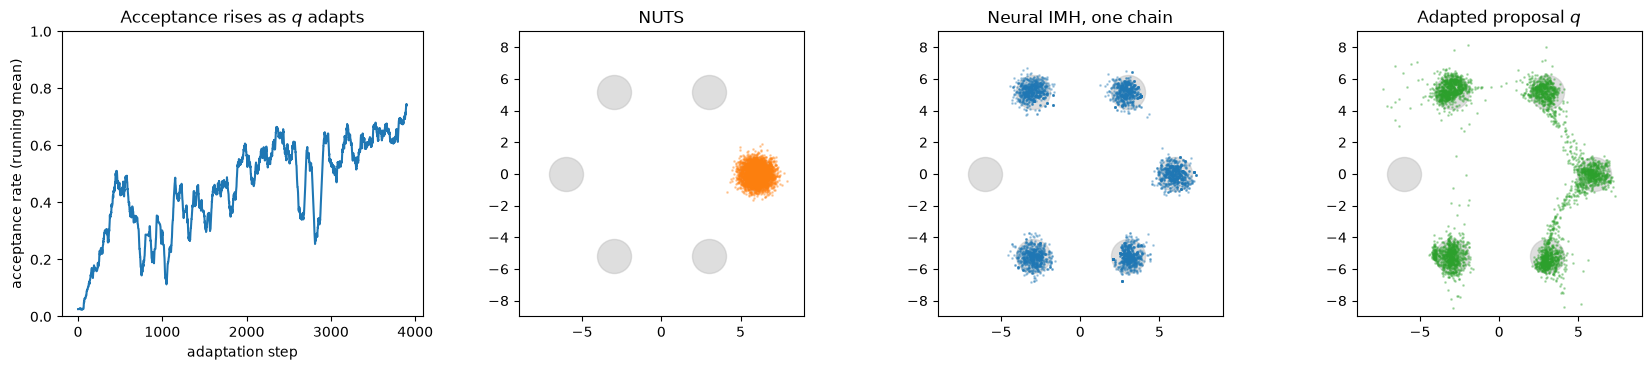

In [12]:
def proposal_samples(params, num=4000):
    return jax.vmap(proposal.sample, (0, None))(jax.random.split(jax.random.key(4), num), params)


def smoothed(values, width=100):
    return jnp.convolve(values, jnp.ones(width) / width, mode="valid")


lim = (-9, 9)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].plot(smoothed(adapted.trace["acceptance_rate"]), color=COLORS["neutra"])
axes[0].set(xlabel="adaptation step", ylabel="acceptance rate (running mean)", ylim=(0, 1),
            title="Acceptance rises as $q$ adapts")
for ax, draws, color, title in [
    (axes[1], mix_nuts["position"], COLORS["nuts"], "NUTS"),
    (axes[2], mix_imh["position"], COLORS["neutra"], "Neural IMH, one chain"),
    (axes[3], proposal_samples(adapted.params), COLORS["flow"], "Adapted proposal $q$"),
]:
    ax.scatter(*mode_means.T, s=600, color=COLORS["reference"], alpha=0.5)
    ax.scatter(*draws.T, s=1, alpha=0.3, color=color, rasterized=True)
    ax.set(xlim=lim, ylim=lim, aspect="equal", title=title)
plt.tight_layout()
plt.show()

The adapted chain jumps between modes, but look at the occupancy: one chain
training its own proposal can *forget* a mode. The proposal only learns from
where the chain goes, so once $q$ underweights a mode the chain stops visiting
it, the buffer stops containing it, and $q$ forgets it further. The chain stays
exact (it is still a valid IMH kernel after adaptation), but a mode the
proposal has lost is visited rarely or, as here, not at all.

### Four chains, one shared proposal

The fix is more data from more places. Run four chains started in different
modes under `jax.vmap(..., axis_name="chain")`, and give `fit_adaptor` the same
`axis_name`: gradients are averaged over chains, so all four train one shared
proposal on everything they see. This time we also fit in blocks:
`every=250, num_fit_steps=250` alternates 250 transitions with 250 Adam steps
on the buffer, still inside the same compiled scan. The total budget is the
same as for the single chain.

In [13]:
NUM_IMH_CHAINS = 4
shared_policy = fit_adaptor(
    maximum_likelihood(proposal), optax.adam(3e-3), data_fn=imh_data,
    every=250, num_fit_steps=250, axis_name="chain",
)


def imh_chain(key, start):
    key_init, key_adapt, key_run = jax.random.split(key, 3)
    state = kernel.init(key_init, start)
    adapted = run(key_adapt, kernel, state, proposal_params, MIX_WARMUP // 2,
                  adaptor=shared_policy, collect=("acceptance_rate",))
    draws = run(key_run, kernel, adapted.state, adapted.params, MIX_DRAWS // NUM_IMH_CHAINS,
                collect=("position", "acceptance_rate"))
    return adapted, draws.trace


start = time.perf_counter()
shared, mix_shared = jax.vmap(imh_chain, axis_name="chain")(
    jax.random.split(jax.random.key(5), NUM_IMH_CHAINS), mode_means[:NUM_IMH_CHAINS]
)
print(f"4 chains: {time.perf_counter() - start:.1f}s")
print(f"acceptance rate after adaptation: {mix_shared['acceptance_rate'].mean():.2f}")
shared_positions = mix_shared["position"].reshape(-1, 2)
print("mode occupancy:", mode_occupancy(shared_positions).round(3))

4 chains: 3.0s


acceptance rate after adaptation: 0.67
mode occupancy: [0.158      0.16100001 0.178      0.15400001 0.17500001 0.17500001]


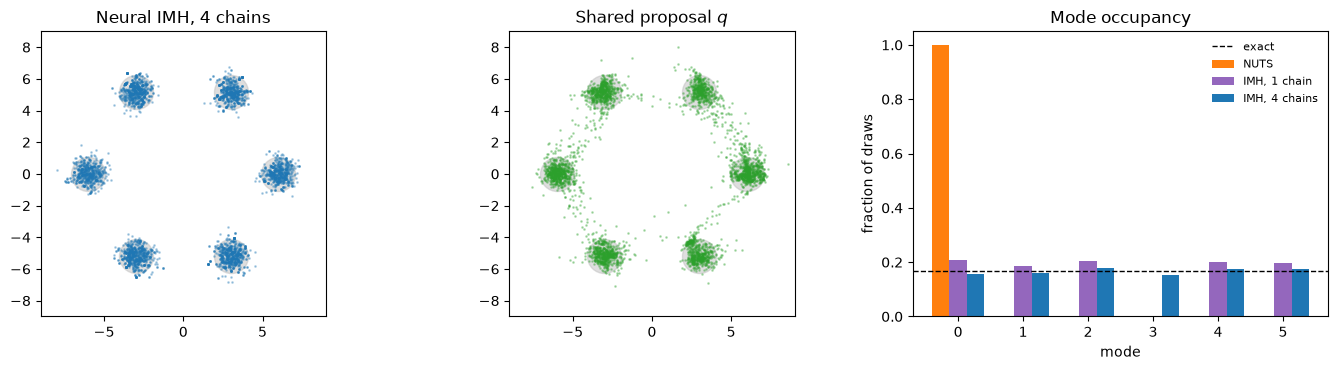

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
shared_params = jax.tree.map(lambda leaf: leaf[0], shared.params)  # identical across chains
for ax, draws, color, title in [
    (axes[0], shared_positions, COLORS["neutra"], "Neural IMH, 4 chains"),
    (axes[1], proposal_samples(shared_params), COLORS["flow"], "Shared proposal $q$"),
]:
    ax.scatter(*mode_means.T, s=600, color=COLORS["reference"], alpha=0.5)
    ax.scatter(*draws.T, s=1, alpha=0.3, color=color, rasterized=True)
    ax.set(xlim=lim, ylim=lim, aspect="equal", title=title)

width = 0.27
modes = jnp.arange(NUM_MODES)
for offset, positions, color, label in [
    (-width, mix_nuts["position"], COLORS["nuts"], "NUTS"),
    (0.0, mix_imh["position"], "tab:purple", "IMH, 1 chain"),
    (width, shared_positions, COLORS["neutra"], "IMH, 4 chains"),
]:
    axes[2].bar(modes + offset, mode_occupancy(positions), width, color=color, label=label)
axes[2].axhline(1 / NUM_MODES, color="k", ls="--", lw=1, label="exact")
axes[2].set(xlabel="mode", ylabel="fraction of draws", title="Mode occupancy")
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
def occupancy_error(positions):
    return 0.5 * float(jnp.abs(mode_occupancy(positions) - 1 / NUM_MODES).sum())


print(f"{'':>14} {'modes visited':>14} {'occupancy TV':>13} {'sampling evals':>15}")
for name, positions, evals in [
    ("NUTS", mix_nuts["position"], int(mix_nuts["num_integration_steps"].sum())),
    ("IMH, 1 chain", mix_imh["position"], MIX_DRAWS),
    ("IMH, 4 chains", shared_positions, MIX_DRAWS),
]:
    print(f"{name:>14} {int((mode_occupancy(positions) > 0.01).sum()):14d} "
          f"{occupancy_error(positions):13.3f} {evals:15,d}")

                modes visited  occupancy TV  sampling evals
          NUTS              1         0.833          16,994
  IMH, 1 chain              5         0.167           4,000
 IMH, 4 chains              6         0.028           4,000


NUTS spends every draw in the mode it started in, an error that no
within-chain diagnostic reveals. The shared proposal covers all six modes in
roughly the right proportions, with one target evaluation (and no gradient)
per step against several gradient evaluations per NUTS step.

## When to use what

| Situation | Use | Why |
| --- | --- | --- |
| Smooth, roughly Gaussian posterior | NUTS with window warmup | Nothing to fix; a flow fit costs more than it saves. |
| Varying curvature, strong nonlinear correlation (funnels, hierarchical models) | `flow_vi` + `neutra` + NUTS | The flow straightens the geometry; NUTS keeps exactness and handles the residual mismatch. |
| Separated modes, low dimension | `imh` with a `density(flow)` proposal, several chains sharing one `fit_adaptor(..., axis_name=...)` | Global proposals jump between modes; acceptance shows how good the fit is. |
| Expensive or non-differentiable target | `imh` with a learned proposal | One density evaluation per step, no gradients. |
| Pilot draws already available (earlier runs, simulations) | `proposal_flow.fit(key, draws)` before `density(proposal_flow)` | Seeds the proposal with modes the chain has not found yet. |

Caveats worth keeping in mind:

- **Both methods stay exact**: NeuTra is a change of variables, and neural IMH
  freezes its proposal after adaptation. (Keeping `fit_adaptor` running while
  you collect draws is adaptive MCMC: fine for exploration, but stop adapting
  for the draws you report.) A poor flow costs efficiency, not
  correctness.
- **Independent proposals degrade with dimension.** The acceptance rate of IMH
  falls quickly as $q$ and $p$ diverge, which happens much sooner in high
  dimension. Watch the acceptance rate during adaptation; if it stays low, prefer a
  local kernel or NeuTra.
- **A global proposal only finds modes it can reach.** Start it broad (as above),
  pre-fit it on pilot draws, and train it from several chains; a mode that
  neither the chains nor the proposal ever visit stays invisible.
- **Count the fitting cost.** Compare total target evaluations, including VI or
  proposal fits, against the effective sample size you get back.